In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
from contextlib import chdir  # gebruikt om functies uit de package te kunnen importeren

# 16-11-2026

## Data inlezen en bekijken

https://zenodo.org/records/3574531 

In the file, the columns correspond to:

    ID: identifier of the animal
    Time: day of the tumor measurement after implantation
    Observation: tumor measurement (in mm3)


In [3]:
with chdir(".."):
    data = pd.read_csv("test_data/LM2-4LUC.txt", sep="\t")
print(data)

     ID  Time  Observation
0     0  22.0   621.290000
1     0  24.0   768.350000
2     0  27.0  1132.300000
3     0  28.0  1239.755000
4     0  32.0  1387.200000
..   ..   ...          ...
578  65  25.0  1060.866744
579  65  27.0  1016.310568
580  65  29.0  1041.071779
581  65  32.0  1901.515650
582  65  34.0  2036.072448

[583 rows x 3 columns]


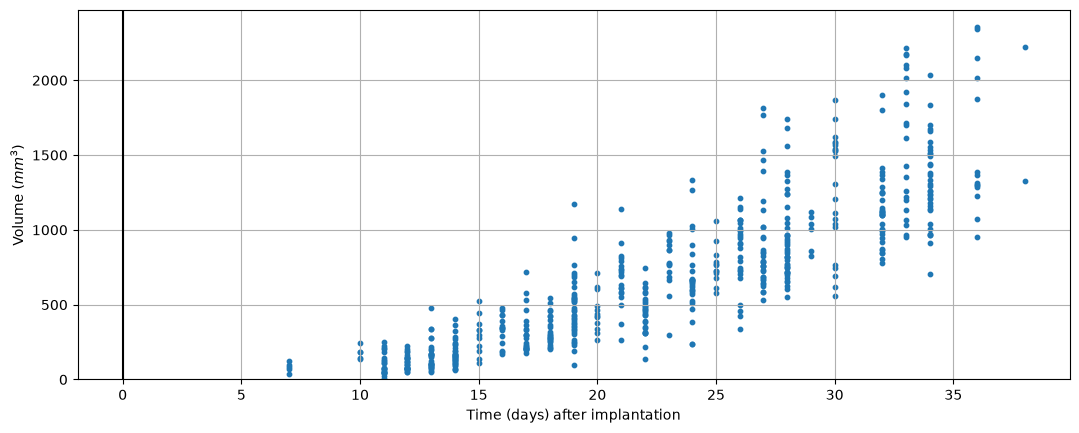

In [4]:
def plot_test_data(data, marker_size = None, title = None):
    plt.figure(figsize=(12.8, 4.8))
    if marker_size:
        plt.scatter(x= data["Time"], y = data["Observation"], s = marker_size)
    else:
        plt.scatter(x= data["Time"], y = data["Observation"])
    plt.ylabel("Volume ($mm^3$)")
    plt.xlabel("Time (days) after implantation")
    plt.grid(visible = True)
    plt.ylim(bottom=0)
    plt.axvline(0.0, color='k') # maakt een verticale zwarte lijn op de x = 0
    if title:
        plt.title(title)

plot_test_data(data, 10)
plt.show()

Dit zijn best veel datapunten en is hierdoor niet overzichtelijk. Ik denk het het eerst nuttiger is om de data per sample (ID) te bekijken. Ik ga filteren op de ID(s) met de meeste datapunten, en deze bekijken.

In [5]:
id_value_counts = data["ID"].value_counts()
# bekijk IDs met de meeste datapunten.
print(id_value_counts[0:10])

ID
33    15
34    15
35    15
36    15
37    15
38    15
51    11
55    11
56    11
57    11
Name: count, dtype: int64


In [6]:
top_value_count_ids = list(id_value_counts[id_value_counts == 15].index) # 15 is mixmaal aantal datapunten voor één ID
print(top_value_count_ids)

top_data = data[data["ID"].isin(top_value_count_ids)]

[33, 34, 35, 36, 37, 38]


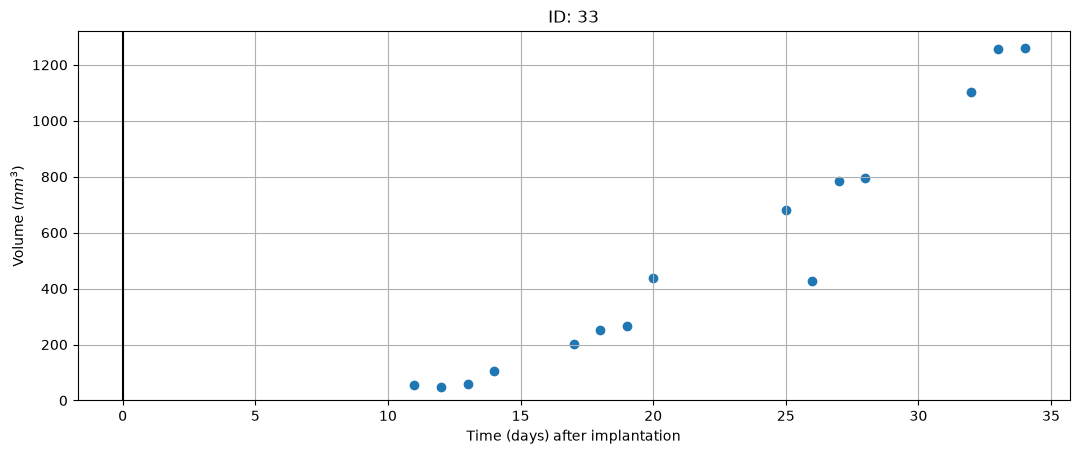

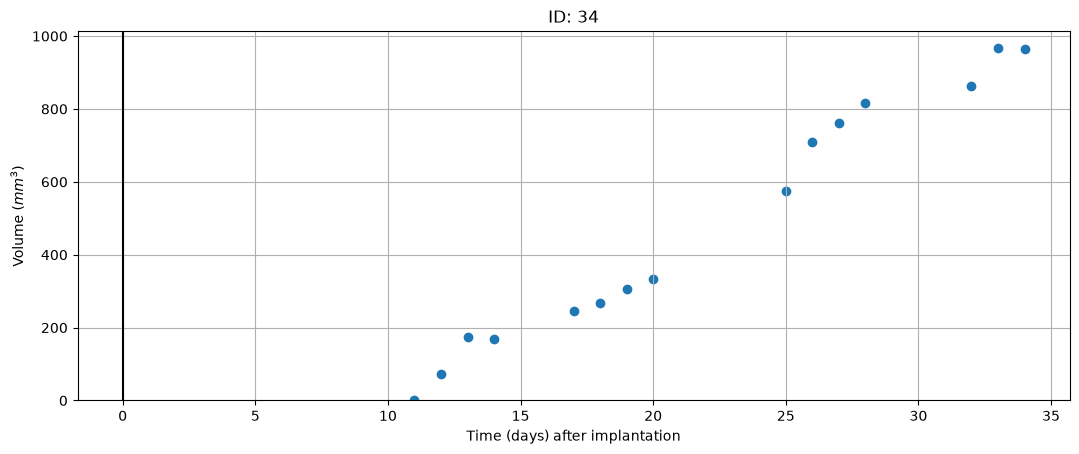

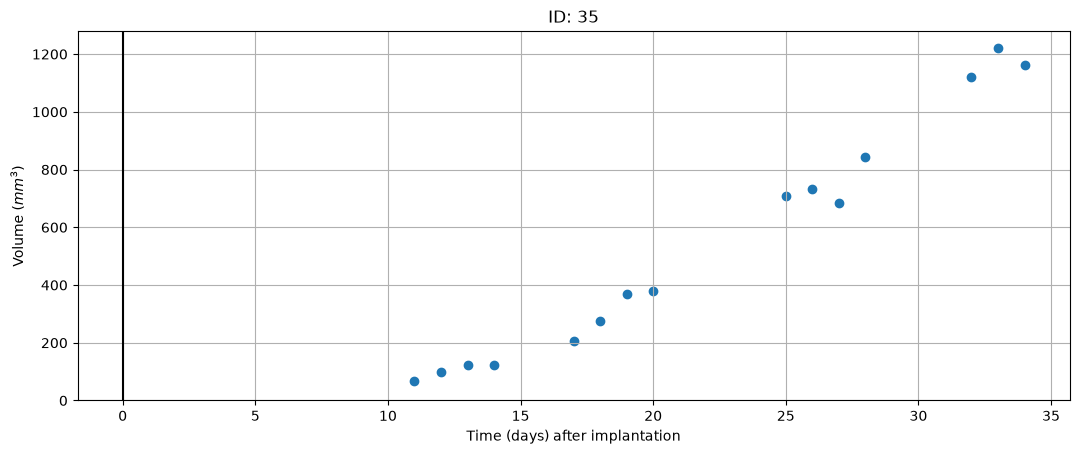

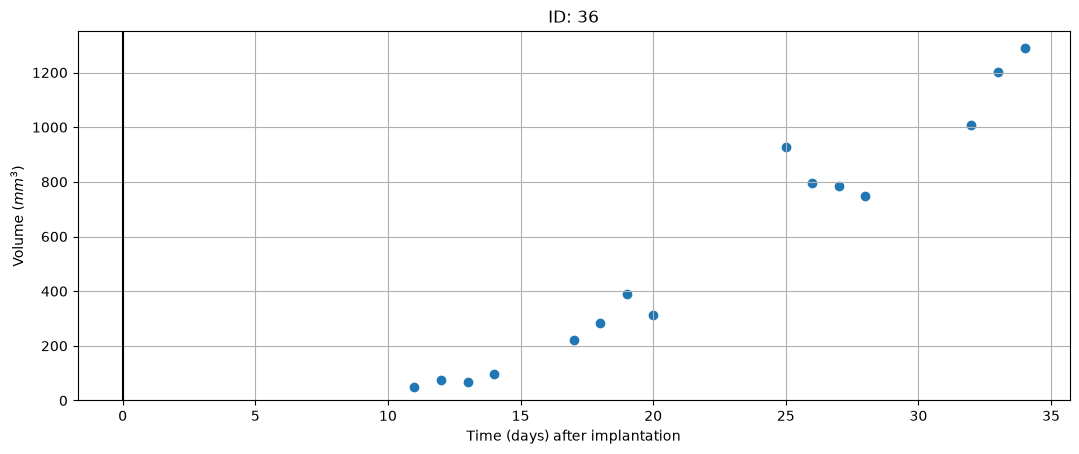

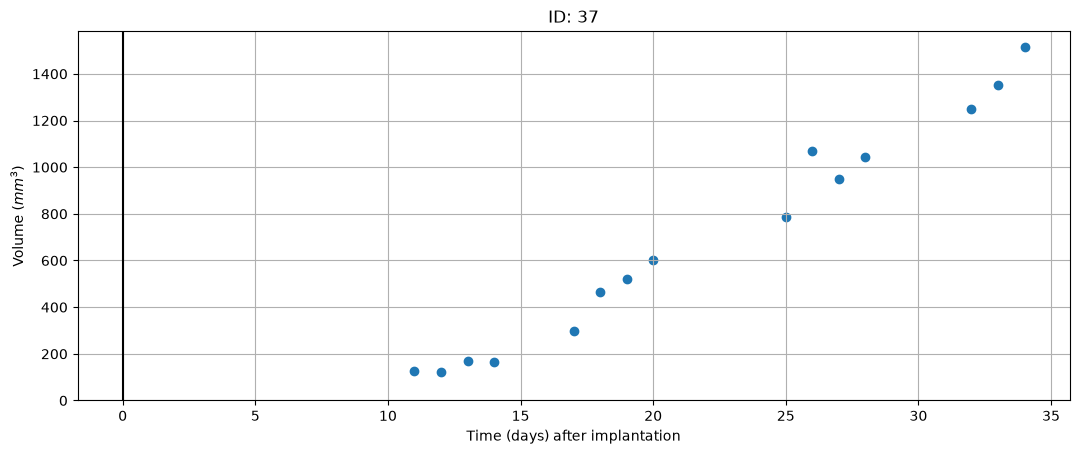

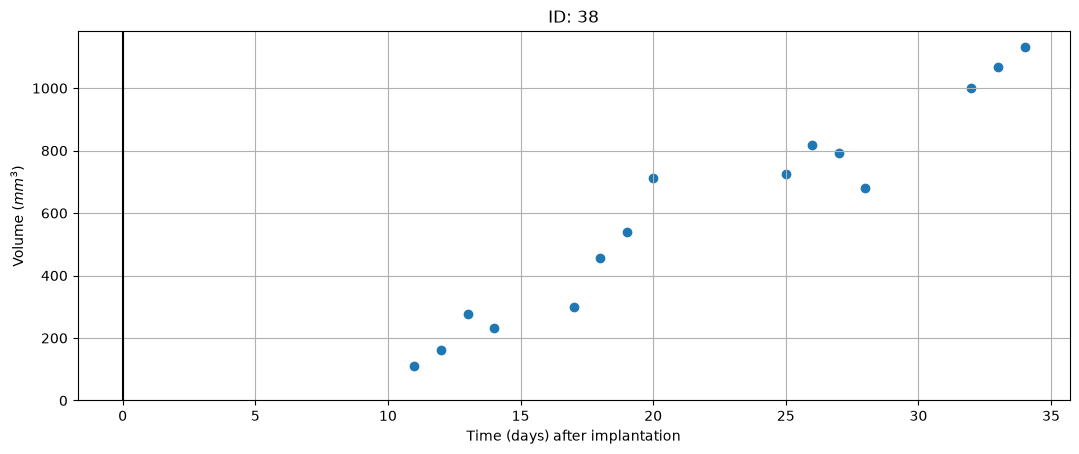

In [7]:
for id in top_value_count_ids:
    plot_test_data(data[data["ID"] == id], title = f"ID: {id}")
    plt.show()

# Workshop 1 implementeren

Hiervoor heb ik de code van Brightspace van workshop 1 gekopieërd en aangepast zodat i.p.v. het SIR model het Bertalanffy model gebruikt, zoals beschreven uit het voorbeeld artikel [Treatment Optimization for Tumor Growth by Ordinary Differential Equations](https://www.researchgate.net/publication/378286328_Treatment_Optimization_for_Tumor_Growth_by_Ordinary_Differential_Equations).

De code hiervoor staat in `package/models.py`.

In [8]:
with chdir(".."):
    from package.models import *

Ik heb voor nu voor de alpha en beta de zelfde waarden laten staan als in de voorbeeld code, omdat ik zelf geen goed beeld heb van wat hier goede waarden voor zouden kunnen zijn.

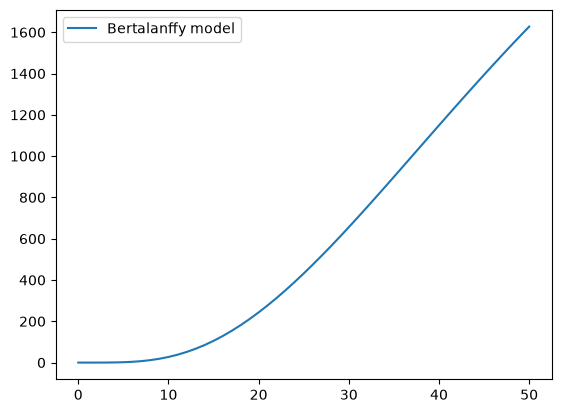

In [9]:
plot_model(*model_tumor_growth(bertalanffy), "Bertalanffy")
plt.show()

Dit lijkt wel te werken. De volgende stap wat ik wil proberen is het (voor zo ver mogelijk) laten overeen komen met de echte data. 

Hiervoor zal ik de parameters van de `bertalanffy` functie handmatig wat aanpassen tot ik iets krijg wat er op lijkt. Ik overlap het ook met de echte data zodat het goed te vergelijken is. Voor het overlappen gebruik ik 1 van de willekeurig gekozen IDs uit de data die veel datapunten heeft die eerder bepaald zijn.

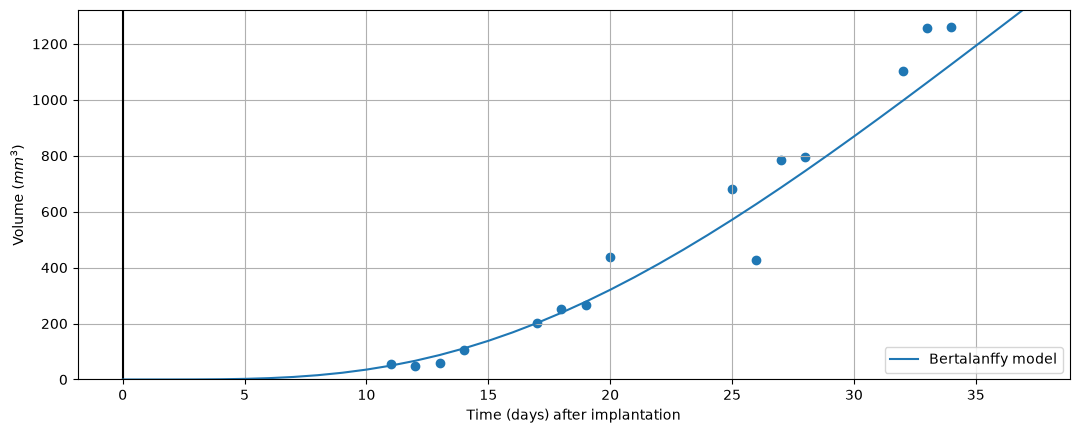

In [10]:
plot_test_data(data[data["ID"] == 33])
plot_model(*model_tumor_growth(bertalanffy, N=37, alpha=1.65), "Bertalanffy")
plt.show()

Dit lijkt opzich wel oke. Ik heb voor het bovenstaande alleen een hogere alpha (groeisnelheid) ingesteld. Ook is de hoveelheid dagen (default 50) veranderd naar 37 (dit is iets later dan laatst gemeten tijdstip voor ID 33). Dit laatste veranderd niet de uitkomst, maar zorgt dat de lijn eerder stopt waardoor het er iets beter uitziet.

Ik wil kijken of iets vergelijkbaars lukt met een andere beta waarde.

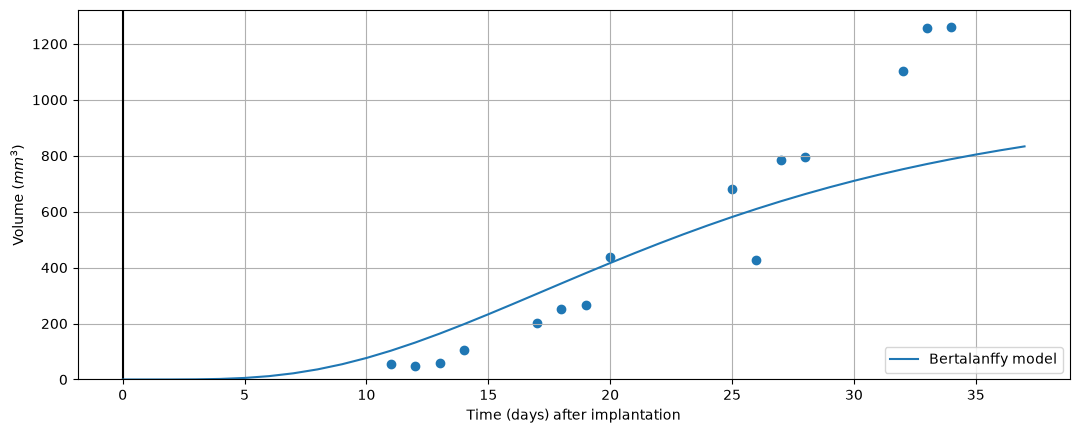

In [11]:
plot_test_data(data[data["ID"] == 33])
plot_model(*model_tumor_growth(bertalanffy, N=37, alpha=2.5, beta=.25), "Bertalanffy")
plt.show()

De beta aanpassen veranderd de vorm van de curve, waardoor de lijn minder goed door de punten heen gaat. Het vorige voorbeeld lijkt dus beter.

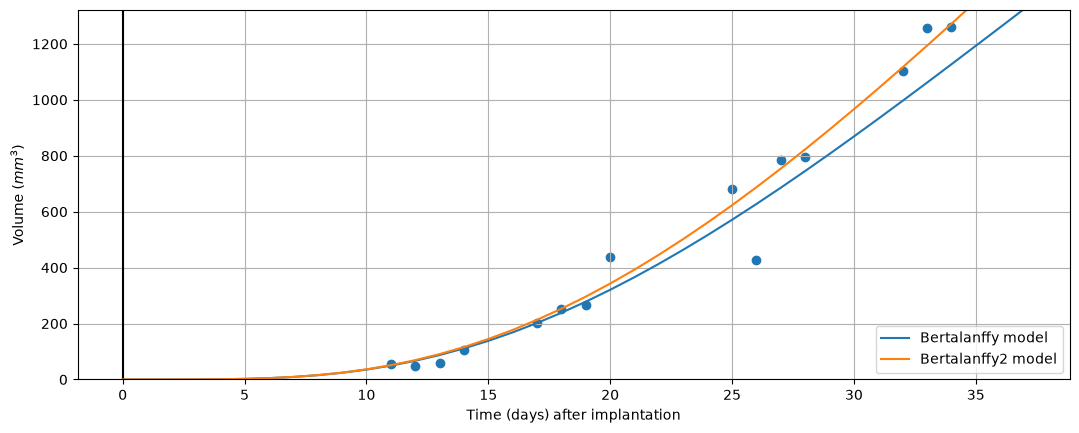

In [12]:
plot_test_data(data[data["ID"] == 33])
plot_model(*model_tumor_growth(bertalanffy, N=37, alpha=1.65), "Bertalanffy")
plot_model(*model_tumor_growth(bertalanffy, N=37, alpha=1.65, beta=.09), "Bertalanffy2")
plt.show()

Hier zou ik net zo lang mee door kunnen spelen, maar het lijkt het me de bedoeling om dit eigenlijk uiteindelijk te automatiseren, en dan ook voor verschillende modellen.

## 18-11-2026

Ik heb de belangrijke functies van de code van gister verplaatst naar een apart .py bestand `package/models.py`. 

Ik heb de code van workshop 2 van Nicole en mijn code voor workshop 1 aangepast zodat het samenwerkt, zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/002c9612b740416abfbf484484b5bfef32e42e72. 

Daarnaast heb ik de repo beetje opgeschoond, zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/ab05d46ba917bb79b0cb07f7b311850e435c2f7b

# 19-11-2026

Ik wil vandaag de theorie en code van workshop 4 gaan verwerken in ons project. Nicole heeft dit al gedaan voor workshop 3, wat ik nodig ben voor workshop 4.

Eerst wil ik even wat etra modellen toevoegen aan `models.py`. Hier staat momenteel nog het Bertalanffy model in. Ik ga ook de 2 ander besproken modellen in het [voorbeeld artikel](https://www.researchgate.net/publication/378286328_Treatment_Optimization_for_Tumor_Growth_by_Ordinary_Differential_Equations) (Logistic en Gompertz) toevoegen. Ik kies deze 2 omdat deze, net zoals het Bertalanffy model, in het artikel goed omschreven zijn. Dit maakt het makkelijker om deze zelf ook te gaan omschrijven in de README uiteindelijk (indien nodig).

De modellen zijn toegevoegd, zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/1deda4a9b00b17da2c62d0dc7be58b3757bbbd0f 

In [13]:
with chdir(".."):
    from package.models import logistic, gompertz

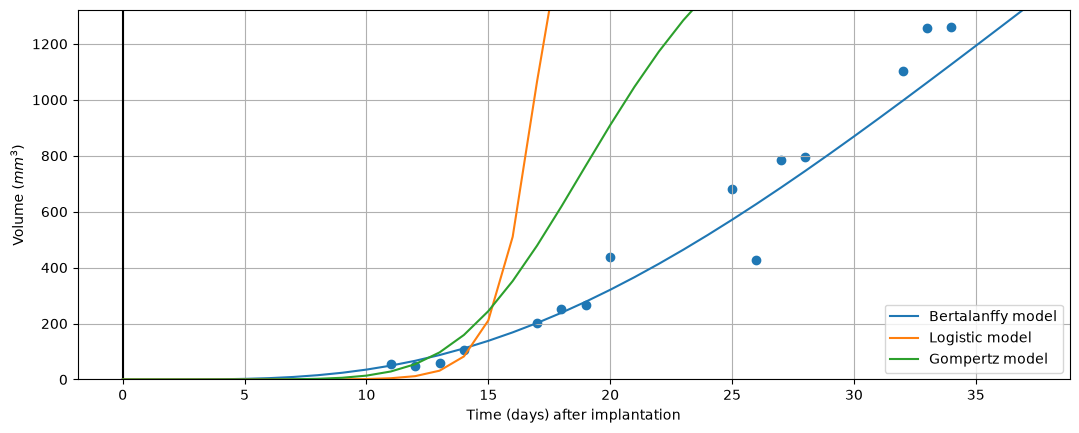

In [20]:
plot_test_data(data[data["ID"] == 33])
plot_model(*model_tumor_growth(bertalanffy, N=37, alpha=1.65), "Bertalanffy")
plot_model(*model_tumor_growth(logistic, N=37, alpha=1.65, beta = 1500), "Logistic")
plot_model(*model_tumor_growth(gompertz, N=37, alpha=1.65, beta = .22), "Gompertz")
plt.show()

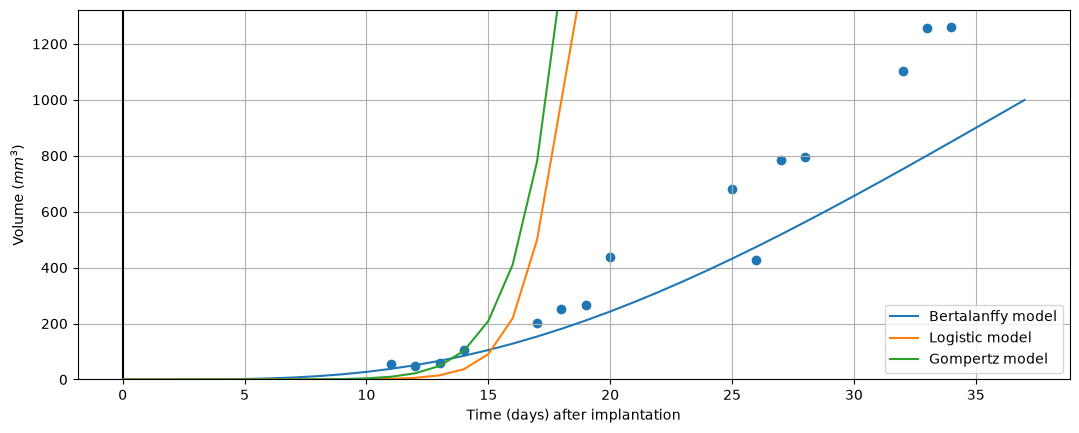

In [19]:
plot_test_data(data[data["ID"] == 33])
plot_model(*model_tumor_growth(bertalanffy, N=37), "Bertalanffy")
plot_model(*model_tumor_growth(logistic, N=37), "Logistic")
plot_model(*model_tumor_growth(gompertz, N=37), "Gompertz")
plt.show()

## Workshop 4

Voor workshop 4 wil ik de BIC, AIC en AICc implementeren door voor elke van deze een functie maken. Hiervoor maak ik een apart bestand `package/model_comparison.py`.

In [ ]:
with chdir(".."):
    from package.model_comparison import BIC, AIC, AICc

Belangrijke uitgangspunten bij het bekijken van vergelijken van de modellen (deze komen uit Brightspace workshop 4!!):  
 - een model past beter bij de data naarmate het een lagere BIC/AIC/AICc oplevert;
 - twee modellen die onderling niet meer dan 2.0 van elkaar verschillen zijn niet significant verschillend van kwaliteit.

In [ ]:
# De MSE is voor nu een random waarde
MSE1 = 0.1
MSE2 = 0.2
n = len(data[data["ID"] == 33])

print("test1")
print(BIC(MSE1, 20, bertalanffy))
print(AIC(MSE1, 20, gompertz))
print(AICc(MSE1, 20, logistic))

print("test2")
print(BIC(MSE2, 20, bertalanffy))
print(AIC(MSE2, 20, gompertz))
print(AICc(MSE2, 20, logistic))

test1
-34.068772765664946
-38.05170185988091
-35.38503519321424
test2
-20.205829154466045
-24.188758248682007
-21.522091582015342


De theorie/code van workshop 4 is geïmplementeerd in `package/model_comparison.py`. Dit bevat functies voor het bepalen van de BIC, AIC en AICc voor modellen. Zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/a3ff9b950101418cce24702746380494e9641297.

Verder viel het me op dat de modellen nu parameter `t` nemen maar deze niet gebruiken. Deze zou denk ik nog weg moeten.

De volgende stap zou zijn de code uit workshop 3 en 4 samen te laten werken.

TODO:  
 - parameter `t` uit de ODE modellen halen? Deze wordt niet gebruikt en kan misschien dus beter weg?

# 22-11-2026

Ik wil vandaag een beginnetje maken aan de use-case notebook. Hiervoor ga ik de al gebruikt test data fitten met behulp van de geschreven functies (in de package folder).

Ik heb een begin gemaakt aan de use-case notebook (zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/b25318207340bfc0bd3ca36e4587dee4b9c5e590).  
Hiervoor heb ik wel wat van de bestaande functie uit hun test bestanden moeten halen en een klein beetje moeten aanpassen (de code werkte nog niet helemaal goed samen, zie eind vorige log). Verder ontbreekt er nog tekst met uitleg, en ook code voor de functies uit model_comparison.py (BIC, AIC en AICc).


# 23-11-2026

Vandaag moet de casus ingeleverd worden, dus gaan we het afmaken.

Hiervoor moet in ieder geval het volgende nog gebeuren:
 - voorbeeld voor BIC, AIC en AICc scores aan notebook toevoegen
 - meer tekst een uitleg in voorbeeld notebook
 - README invullen? Op Brightspace staat daar het volgende over:
    - "*een uitgebreid markdown readme document dat niet alleen de technische specificaties en afhankelijkheden van je module/package benoemt, maar dat aan de gebruiker ook bondige achtergrondinformatie geeft over de gebruikte modellen en technieken (incl. referenties);*"
    - Echter staat er niks in de Rubric over de README, dus ik weet niet tot hoe ver dit nodig is. In de Rubric (gehaald van Brightspace) staat voor casus A:
      - "*Toelichtingen in je notebook geven blijk van begrip omtrent de werking van gebruikte modellen. Analysestappen volgen elkaar logisch op en worden voldoende gemotiveerd. Resultaten worden kritisch beoordeeld en van een biologische interpretatie voorzien. [LUK 1, 2, 3, 5]*"
      - "*Je notebook is reproduceerbaar en navolgbaar. Je code werkt correct en is voldoende efficiënt. Je maakt gebruik van geschikte modules van derden en/of eigen implementaties. Je hebt de versiegeschiedenis op een traceerbare manier bijgehouden. [LUK 1, 4, 5]*"
   - Op basis van de Rubric lijkt het beter om te focussen op de notebook. Dit gaan we dus ook doen. Voor de in de notebook gaat Nicole uitleg  toevoegen over de theorie/code in workshop 2 en 3, en ik voor workshop 1 en 4 (de gedeeltes de we zelf gedaan hebben).


Het toevoegen van de BIC, AIC en AICc aan de usecase notebook heb ik gedaan, zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/72a6908c1a56a47b8cecbabd37e12378ce1a47ce. 

Verder heb ik ook tussendoor wat kleine aanpassingen gemaakt aan de code, zodat het wat dynamischer met elkaar werkt, zie commits: https://github.com/Nikkieeex/Dynamic_Modelling/commit/1a04cc90c976a0323598ad645bdb021c605248ef en https://github.com/Nikkieeex/Dynamic_Modelling/commit/daa6d3cc4577b29b1b36198b02a88b606bd2e1b5.   
Dit zorgde ervoor dat het maken van de use-case notebook makkelijker wou, en ook dat de code er in de use-case notebook er netter uitzag.

Ik heb nu ook wat tekst toegevoegd aan de notebook. Dit is wat uitleg over alle modellen, en ook over de score metrieken (MSE, BIC, AIC, en AICc), zie commit: https://github.com/Nikkieeex/Dynamic_Modelling/commit/ae12f6330659160dc4b3fd427e5edf1e9635ca88.

Zometeen gaan we tot slot nog even alles na kijken, en daarna het project inleveren.
